# Aufgabe 12.4 – Multivariate Zeitreihenregression

**Ziel:** AppliancesEnergy mit Zeitreihen-kNN, Time Series Forest und einem CNN
vorhersagen und die Fehler auf demselben TEST-Split vergleichen.
[Offizielle Aufgabe 12.4](https://noxthot.github.io/ws26_industrial_datascience_manuscript/1_act1/8_self_study_session3.html),
[Kurskapitel 9](https://noxthot.github.io/ws26_industrial_datascience_manuscript/1_act1/5_1_timeseries_regression.html),
[TSER-Originalbeschreibung](https://doi.org/10.5281/zenodo.3902637),
[verwendeter aeon-Datensatz](https://zenodo.org/records/18484626), gelesen 26.10.2026.
KI-Unterstützung: Codex. **SCIENTIFICALLY APPROVED – TECHNICALLY VALIDATED – AWAITING FINAL MERGE AUTHORIZATION.**

## Daten und Versuchsaufbau
Die Originaldateien enthalten 95 TRAIN- und 42 TEST-Fälle, je 24 Kanäle mit 144 Werten.
Die Zielgröße ist laut TSER-Beschreibung Gesamtenergie in kWh. Dies ist eine bereits
aufbereitete Benchmarkfassung des UCI-Datensatzes, keine einzelne Wh-Messung aus dessen
19.735 Originalzeilen. Die ältere Beschreibung nennt 138 Reihen, die gelieferten
Dateien enthalten tatsächlich 137. Herkunft, Lizenz und Hashes: `docs/APPLIANCES_SOURCE.md`.
Die Kanalreihenfolge und genaue zeitliche Zuordnung sind im Header nicht dokumentiert;
Abtastindizes werden deshalb nicht als gesicherte Uhrzeiten bezeichnet.

TRAIN und TEST bleiben unverändert getrennt. Alle Kanal-Mittelwerte und
Standardabweichungen stammen nur aus TRAIN. Fehlende/ungültige Werte werden abgewiesen;
keine Imputation, Längenanpassung oder neue Fensterbildung. Auch die CNN-Zielskalierung
wird nur aus TRAIN berechnet. TEST dient ausschließlich der abschließenden Bewertung.
Der Benchmark-Split ist kein belegter chronologischer oder gebäudeunabhängiger Test.

## Die drei Verfahren
**DTW-3-NN:** Für eine neue Reihe werden die drei ähnlichsten TRAIN-Reihen anhand
einer multivariaten DTW-Distanz gesucht. Deren Zielwerte werden gleich gewichtet
gemittelt: ŷ = (y₁+y₂+y₃)/3. Ein gemeinsamer DTW-Pfad verbindet die Kanäle;
window=0,1 begrenzt die zeitliche Verschiebung. k=3 ist eine feste Annahme, kein Optimum.

**Time Series Forest:** 200 Bäume nutzen Mittelwert, Standardabweichung und Steigung
zufälliger Kanalintervalle. Quadratischer Fehler steuert die Baumaufteilung;
Blattmittelwerte und anschließend die Baumvorhersagen werden gemittelt.
`n_intervals='sqrt'`, Mindestlänge 3, Seed 42, ein Thread, kein Zeitlimit.
Skalierung ist für Bäume nicht nötig, hält hier aber die Eingaben vergleichbar.

**CNN-Regressor:** Conv1d 24→16 (Kernel 7), ReLU, MaxPool 2; Conv1d 16→32
(Kernel 5), ReLU, AdaptiveAvgPool auf 8 Positionen; lineare Ausgabe 256→1.
Padding erhält die Länge vor Pooling. 5.553 trainierbare Parameter;
eine kontinuierliche Ausgabe ohne Softmax. Die Pooling-Darstellung fasst lokale
Muster zusammen, kann aber Details verlieren. PyTorch-CPU vermeidet eine zusätzliche
TensorFlow-Umgebung. Adam 0,001, Batch 16, 60 feste Epochen, Seed 42, MSE auf
TRAIN-standardisierten Zielen. Vor Auswertung wird ŷ = ẑ·σTRAIN+μTRAIN zurückgerechnet.
Keine separate Validierung, kein Early Stopping oder Tuning nach TEST-Ergebnissen.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sessions.ch12.regression import load_appliances,fit_regressors,predict_regressors,evaluate_regressors,SOURCE,SEED,EPOCHS,KNN_CONFIG,FOREST_CONFIG
from sessions.ch12.classification import transform
ROOT=Path.cwd();OUT=ROOT/'outputs/ch12/exercise_12_4';OUT.mkdir(parents=True,exist_ok=True)
x_train,y_train=load_appliances('TRAIN');x_test,y_test=load_appliances('TEST')
fitted=fit_regressors(x_train,y_train)
predictions,predict_seconds=predict_regressors(fitted,x_test)
metrics=evaluate_regressors(y_test,predictions)
metrics.to_csv(OUT/'metrics.csv',index=False)
export=pd.DataFrame({'case':np.arange(len(y_test)),'true_kwh':y_test})
for name,column in [('DTW 3-NN','knn_kwh'),('Time Series Forest','forest_kwh'),('CNN','cnn_kwh')]:export[column]=predictions[name]
export.to_csv(OUT/'predictions.csv',index=False)
fitted['history'].to_csv(OUT/'cnn_training.csv',index=False)
np.savez_compressed(OUT/'cnn_weights.npz',**{key:value.detach().cpu().numpy() for key,value in fitted['models']['CNN'].state_dict().items()})
forest=fitted['models']['Time Series Forest']
summary={'train_shape':list(x_train.shape),'test_shape':list(x_test.shape),'missing':int(np.isnan(x_train).sum()+np.isnan(x_test).sum()),'target_unit':'kWh (original TSER description)','seed':SEED,'epochs':EPOCHS,'knn_config':KNN_CONFIG,'forest_config':FOREST_CONFIG,'forest_trees':len(forest.estimators_),'forest_interval_draws':forest.total_intervals_,'cnn_parameters':sum(p.numel() for p in fitted['models']['CNN'].parameters()),'train_channel_mean':fitted['scaler'][0].ravel().tolist(),'train_channel_scale':fitted['scaler'][1].ravel().tolist(),'train_target_mean':fitted['target_scaler'][0],'train_target_scale':fitted['target_scaler'][1],'fit_seconds':fitted['fit_seconds'],'predict_seconds':predict_seconds,'negative_predictions':{k:int((v<0).sum()) for k,v in predictions.items()},'raw_sha256':SOURCE['files']}
(OUT/'summary.json').write_text(json.dumps(summary,indent=2)+'\n',encoding='utf-8')
display(metrics.round(6));print('TRAIN/TEST:',x_train.shape,x_test.shape)
print('Fit-Zeiten:',fitted['fit_seconds']);print('Predict-Zeiten:',predict_seconds)

,method,rmse,mae
0,DTW 3-NN,3.509225,2.711349
1,Time Series Forest,2.109183,1.685254
2,CNN,3.614675,2.608054


TRAIN/TEST: (95, 24, 144) (42, 24, 144)
Fit-Zeiten: {'DTW 3-NN': 0.02807050000410527, 'Time Series Forest': 7.341765400007716, 'CNN': 3.8842076000000816}
Predict-Zeiten: {'DTW 3-NN': 0.960726400007843, 'Time Series Forest': 0.7538347000081558, 'CNN': 0.006512799998745322}


## Eingabe und Trainingsverlauf
Dargestellt werden ausschließlich die ersten drei Kanäle des ersten TRAIN-Falls,
standardisiert mit dem gemeinsamen TRAIN-Skalierer. Alle 24 Kanäle gehen ins Modell.
Der mittlere Batch-Trainingsverlust ist keine Validierungskurve; seine Abnahme beweist
weder gute TEST-Leistung noch für sich genommen Overfitting.

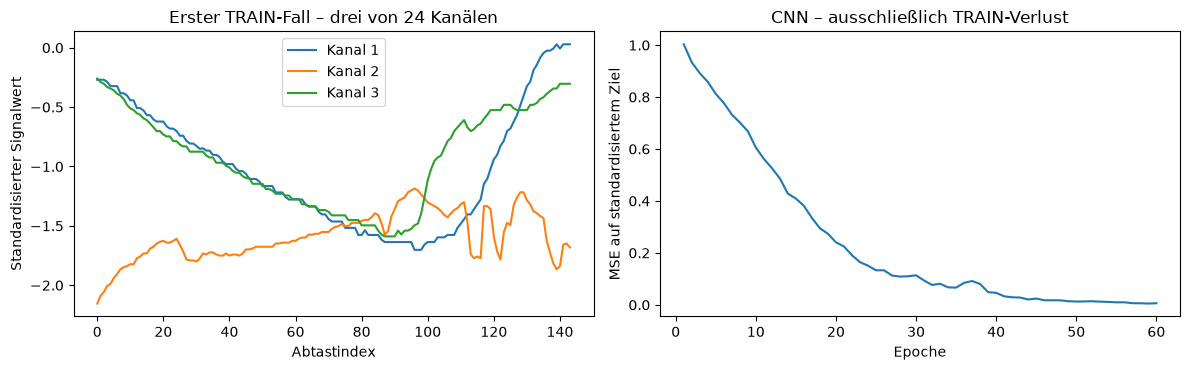

In [2]:
fig,axes=plt.subplots(1,2,figsize=(12,3.8))
prepared=transform(x_train,fitted['scaler'])
for c in range(3):axes[0].plot(np.arange(144),prepared[0,c],label=f'Kanal {c+1}')
axes[0].set(title='Erster TRAIN-Fall – drei von 24 Kanälen',xlabel='Abtastindex',ylabel='Standardisierter Signalwert');axes[0].legend()
history=fitted['history'];axes[1].plot(history.epoch,history.train_standardized_mse)
axes[1].set(title='CNN – ausschließlich TRAIN-Verlust',xlabel='Epoche',ylabel='MSE auf standardisiertem Ziel')
fig.tight_layout();fig.savefig(OUT/'01_input_and_training.png',dpi=150,bbox_inches='tight');plt.show()

## Vergleich auf dem identischen TEST-Split
RMSE = √(Σ(y−ŷ)²/n) gewichtet große Fehler stärker; MAE = Σ|y−ŷ|/n beschreibt
die mittlere absolute Abweichung. Beide werden in kWh auf den ursprünglichen
Zielwerten berechnet. Kleiner ist besser; Accuracy und Confusion-Matrizen passen
nicht zu diesen kontinuierlichen Zielen. Die gestrichelte Identitätsgerade zeigt
perfekte Vorhersagen. Gleiche Skalen erlauben einen direkten grafischen Vergleich.

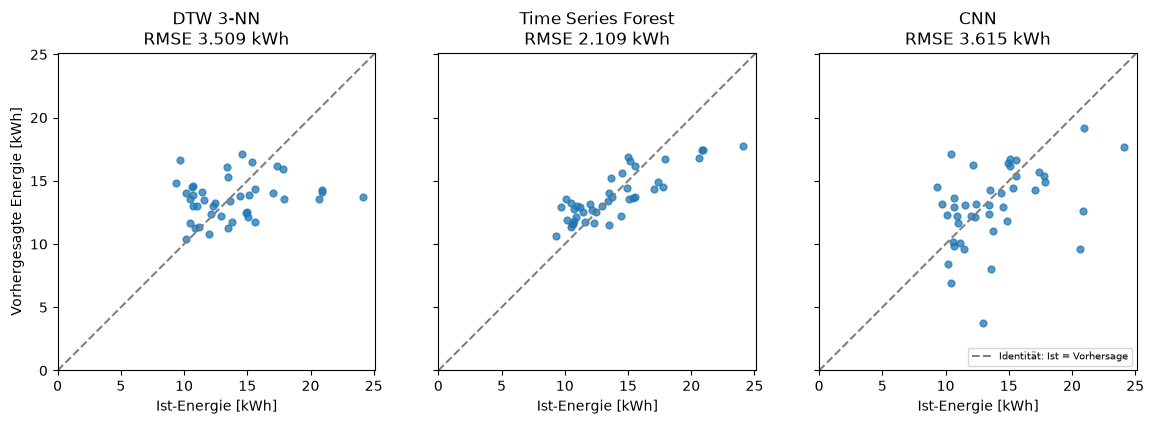

**Beobachtung:** Die RMSE-Reihenfolge in diesem Lauf lautet Time Series Forest (2.1092 kWh) < DTW 3-NN (3.5092 kWh) < CNN (3.6147 kWh). Dies ist ein deskriptiver Vergleich des festen TEST-Splits, keine allgemeine Rangfolge.

Negative Vorhersagen (ohne nachträgliches Abschneiden): {'DTW 3-NN': 0, 'Time Series Forest': 0, 'CNN': 0}


In [3]:
fig,axes=plt.subplots(1,3,figsize=(12,4),sharex=True,sharey=True)
all_values=np.concatenate([y_test,*predictions.values()]);low=min(0,float(all_values.min())-1);high=float(all_values.max())+1
for ax,(name,predicted) in zip(axes,predictions.items()):
    score=metrics.set_index('method').loc[name]
    ax.scatter(y_test,predicted,s=24,alpha=.75)
    ax.plot([low,high],[low,high],'--',color='grey',label='Identität: Ist = Vorhersage')
    ax.set(title=f'{name}\nRMSE {score.rmse:.3f} kWh',xlabel='Ist-Energie [kWh]',xlim=(low,high),ylim=(low,high));ax.set_aspect('equal',adjustable='box')
axes[0].set_ylabel('Vorhergesagte Energie [kWh]');axes[2].legend(fontsize=7,loc='lower right')
fig.tight_layout();fig.savefig(OUT/'02_predictions.png',dpi=150,bbox_inches='tight');plt.show()
ranking=metrics.sort_values('rmse')
display(Markdown('**Beobachtung:** Die RMSE-Reihenfolge in diesem Lauf lautet '+ ' < '.join(f'{r.method} ({r.rmse:.4f} kWh)' for r in ranking.itertuples())+'. Dies ist ein deskriptiver Vergleich des festen TEST-Splits, keine allgemeine Rangfolge.'))
print('Negative Vorhersagen (ohne nachträgliches Abschneiden):',summary['negative_predictions'])

## Einordnung und Grenzen
Die Reihenfolge kann vom Fehlermaß abhängen: RMSE gewichtet große Abweichungen
stärker als MAE. Die Tabelle und der berechnete Ergebnistext geben die Werte des
jeweiligen Laufs wieder. Ein Ergebnis auf diesem Split ist kein allgemeiner
Überlegenheitsnachweis. Deterministische Wiederholungen wurden innerhalb derselben
Plattform geprüft; zwischen Windows und Linux wurden leicht abweichende CNN-Werte
beobachtet. Ein fester Seed garantiert keine plattformübergreifende Bitgleichheit.

Die Fehler beschreiben Energie-Schätzungen aus vollständigen Sensorfenstern.
Das Experiment belegt keine Vorhersage zukünftiger Zeiträume, keine Kausalität und
keine Übertragbarkeit auf andere Häuser. Modelle können Eingabeähnlichkeit und lokale
Muster unterschiedlich nutzen; aus der Rangfolge allein folgt keine Erklärung der
physikalischen Ursachen. Es wurde keine zusätzliche Studie zur Modellwahl durchgeführt.

Nur 95 Trainingsfälle, ein Seed und der vorgegebene Split begrenzen die Aussagekraft.
Kein separates Validierungsset, keine Seed-Wiederholungen, Konfidenzintervalle oder
Signifikanztests. Alle Einstellungen sind begründete Ausgangsannahmen, keine belegten
Optima. Die Zielstandardisierung des CNN wird vor jeder Metrik zurückgenommen.
Anpassungen von Lernrate, Epochen oder DTW-Fenster an TEST wären Datenleckage und
wurden nicht vorgenommen. Negative Ausgaben würden offen berichtet und nicht
nachträglich zur Verbesserung der Kennzahlen abgeschnitten.

**Lernfragen:** Wie unterscheiden sich Nachbarmittelwert, Baumensemble und CNN-Ausgabe?
Warum ist eine Rücktransformation vor RMSE notwendig? Welche unabhängige Studie wäre
für eine verallgemeinerbare Modellentscheidung erforderlich?